# Klasyfikacja zadań matematycznych (NLP)

Zadanie z konkursu Kaggle [Classification of Math Problems by Kasut Academy](https://www.kaggle.com/competitions/classification-of-math-problems-by-kasut-academy): przypisać treść zadania do jednej z 8 kategorii matematycznych (algebra, geometria, analiza, prawdopodobieństwo, teoria liczb, kombinatoryka, algebra liniowa, algebra abstrakcyjna).

**Podejście:** własny preprocessing tekstu z formułami LaTeX, wektoryzacja TF-IDF (n-gramy 1-3), klasyfikatory XGBoost i CatBoost.

**Dane:** pliki `train_math.csv` i `test_math.csv` pochodzą z konkursu i nie są dołączone do repozytorium. Aby uruchomić notebook, pobierz je ze strony konkursu i umieść obok notebooka. Wymagane biblioteki są w `requirements.txt`.

In [5]:
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import GridSearchCV
from wordcloud import STOPWORDS, WordCloud
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

### Czym jest wektoryzacja w NLP?

Wektoryzacja to proces przekształcania danych tekstowych (słów, zdań, dokumentów) w numeryczne wektory, które mogą być przetwarzane przez algorytmy uczenia maszynowego. Umożliwia to modelom rozumienie i analizę języka naturalnego.

### Techniki wektoryzacji

#### 1. Bag of Words (BoW)

Model „torby słów” reprezentuje tekst jako zbiór słów i ich częstotliwości, ignorując gramatykę i kolejność słów. Każdy dokument jest przedstawiany jako wektor liczby wystąpień słów.

#### 2. Term Frequency-Inverse Document Frequency (TF-IDF)

TF-IDF ocenia znaczenie słowa w dokumencie w kontekście całego korpusu. Często używane słowa w danym dokumencie, które są rzadkie w innych, otrzymują wyższe wagi.

#### 3. Count Vectorizer

Podobny do BoW, Count Vectorizer przekształca tekst w wektory na podstawie liczby wystąpień każdego słowa w dokumencie.

## Wczytanie i eksploracja danych

In [24]:
dane = pd.read_csv("train_math.csv")
dane

,Question,label
0,A solitaire game is played as follows. Six di...,3
1,2. The school table tennis championship was he...,5
2,"Given that $x, y,$ and $z$ are real numbers th...",0
3,$25 \cdot 22$ Given three distinct points $P\l...,1
4,I am thinking of a five-digit number composed ...,5
...,...,...
10184,Is there a first- or second-degree polynomial ...,0
10185,4. Let the side lengths of $\triangle A B C$ b...,1
10186,A triangular array of squares has one square i...,5
10187,Suppose we are given seven points that are equ...,1


| Label | Topic                              |
|-------|------------------------------------|
| 0     | Algebra                            |
| 1     | Geometry and Trigonometry          |
| 2     | Calculus and Analysis              |
| 3     | Probability and Statistics         |
| 4     | Number Theory                      |
| 5     | Combinatorics and Discrete Math   |
| 6     | Linear Algebra                     |
| 7     | Abstract Algebra and Topology      |


In [25]:
dane.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10189 entries, 0 to 10188
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Question  10189 non-null  object
 1   label     10189 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 159.3+ KB


In [26]:
dane['label'].value_counts()

,count
label,
0,2618
1,2439
5,1827
4,1712
2,1039
3,368
6,100
7,86


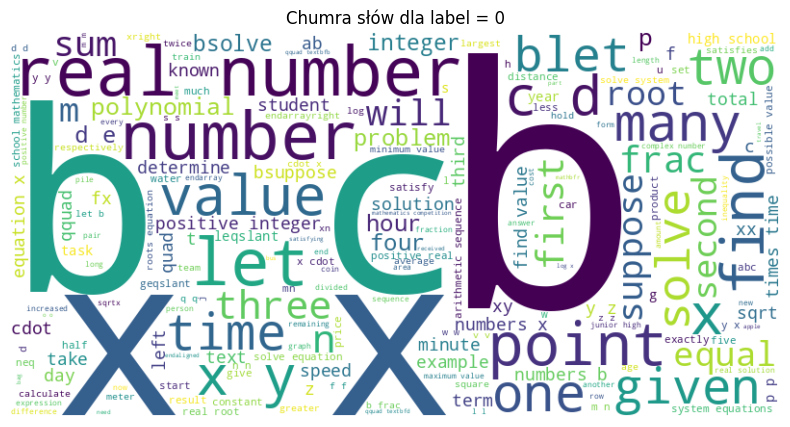

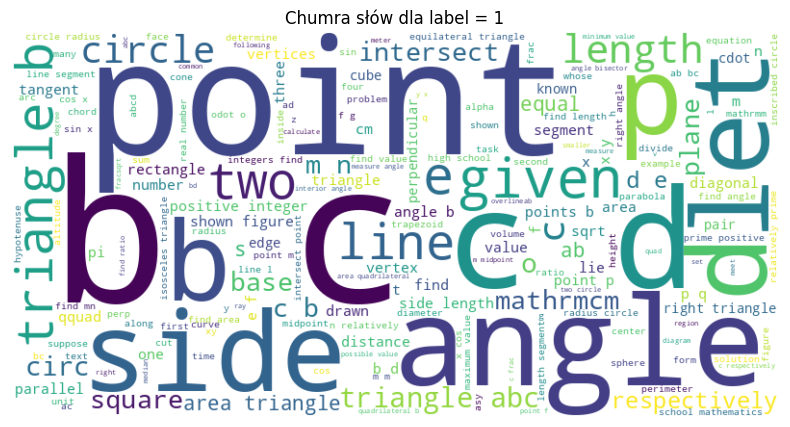

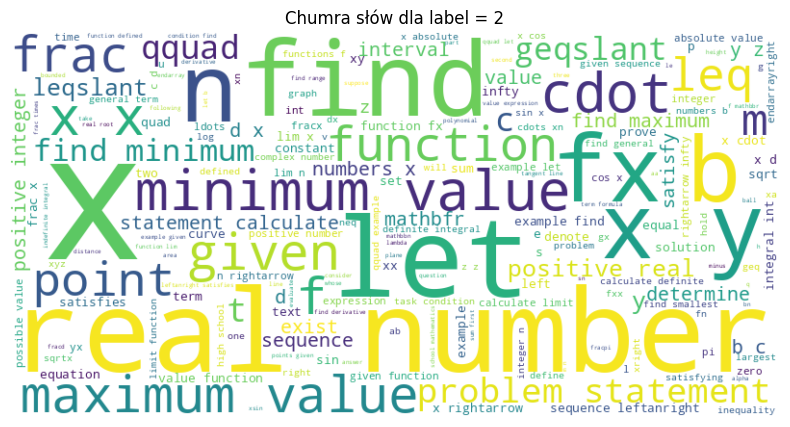

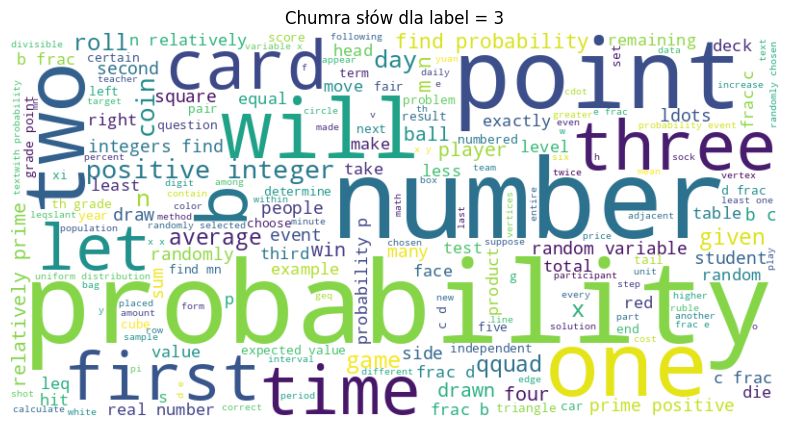

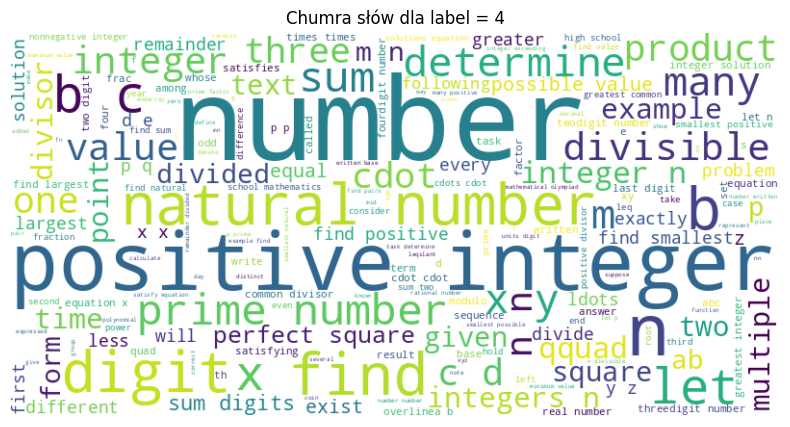

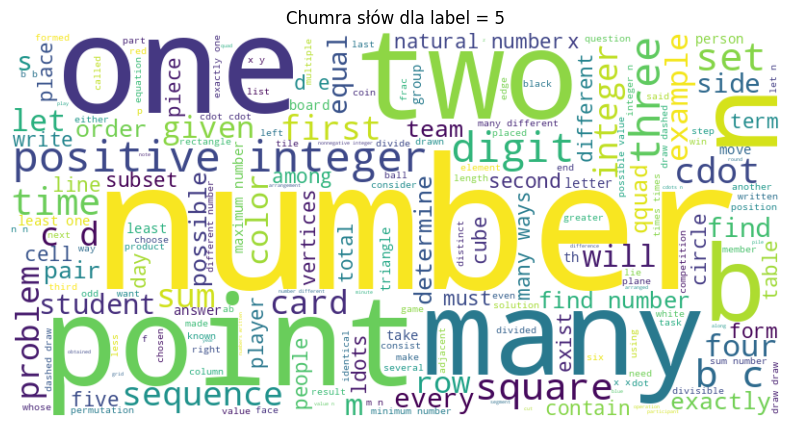

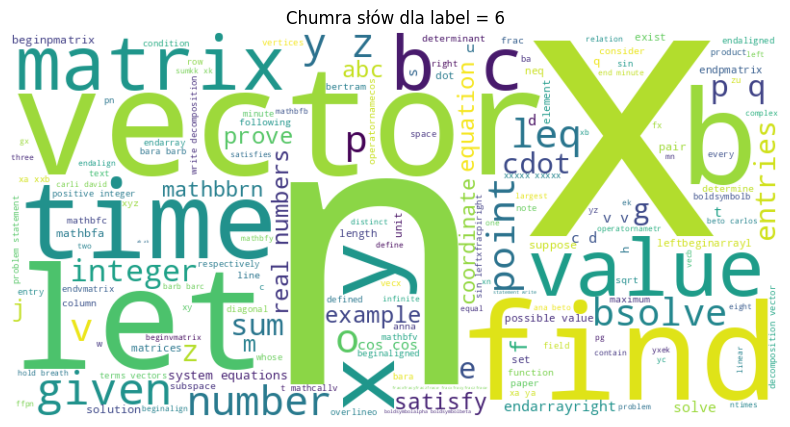

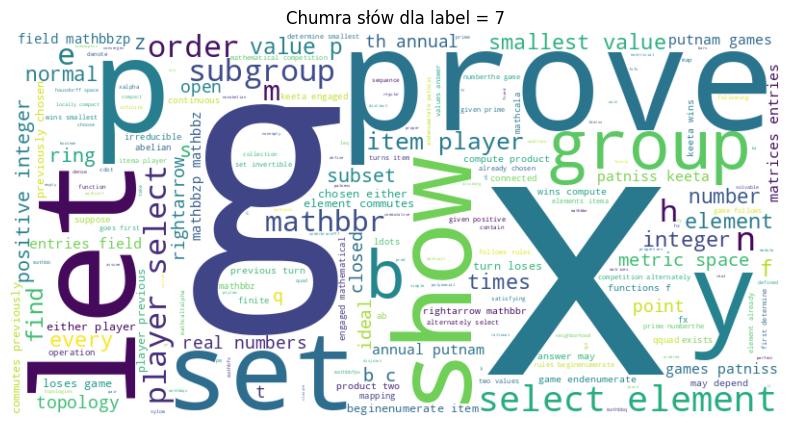

In [27]:
for i in dane['label'].sort_values().unique():
    text = ' '.join(dane[dane['label'] == i]['Question'].astype(str))
    text = re.sub(r'[^A-Za-z\s]', '', text)
    text = text.lower()

    stopwords = set(STOPWORDS)
    text = ' '.join(word for word in text.split() if word not in stopwords)
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f"Chmura słów dla label = {i}")
    plt.show()

## Podział na zmienną niezależną i zależną

In [27]:
X = dane.drop(columns=['label'])
y = dane['label']

## Preprocessing

In [28]:
def math_text_preprocessor(text: str) -> str:
    """Zaawansowany preprocessor, który zachowuje i oznacza cenne informacje."""
    if not isinstance(text, str):
        return ""

    # Zachowaj zawartość formuł, ale oznacz je
    text = re.sub(r'\$(.*?)\$', r' MATH_EXPR \1 MATH_EXPR ', text)
    # Przekształć komendy LaTeX w cechy
    text = re.sub(r'\\\w+', lambda m: ' LATEX_' + m.group(0)[1:] + ' ', text)
    # Normalizuj liczby
    text = re.sub(r'\d+', ' NUM ', text)
    # Usuń niepotrzebną interpunkcję
    text = re.sub(r'[^\w\s]', ' ', text)

    return text.lower().strip()

In [29]:
dane['processed_text'] = dane['Question'].apply(math_text_preprocessor)

In [30]:
dane

,Question,label,processed_text
0,A solitaire game is played as follows. Six di...,3,a solitaire game is played as follows six di...
1,2. The school table tennis championship was he...,5,num the school table tennis championship was...
2,"Given that $x, y,$ and $z$ are real numbers th...",0,given that math_expr x y math_expr and ma...
3,$25 \cdot 22$ Given three distinct points $P\l...,1,math_expr num latex_cdot num math_expr ...
4,I am thinking of a five-digit number composed ...,5,i am thinking of a five digit number composed ...
...,...,...,...
10184,Is there a first- or second-degree polynomial ...,0,is there a first or second degree polynomial ...
10185,4. Let the side lengths of $\triangle A B C$ b...,1,num let the side lengths of math_expr late...
10186,A triangular array of squares has one square i...,5,a triangular array of squares has one square i...
10187,Suppose we are given seven points that are equ...,1,suppose we are given seven points that are equ...


In [33]:
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", None)

### Preprocessing

Funkcja `math_text_preprocessor` zachowuje informacje ze wzorów: treść między znakami `$` jest oznaczana (`MATH_EXPR`), komendy LaTeX zamieniane na osobne cechy (`LATEX_...`), a liczby na `NUM`. Poniżej kilka przykładów zadań po przetworzeniu.

In [34]:
dane.iloc[0]

,0
Question,"A solitaire game is played as follows. Six distinct pairs of matched tiles are placed in a bag. The player randomly draws tiles one at a time from the bag and retains them, except that matching tiles are put aside as soon as they appear in the player's hand. The game ends if the player ever holds three tiles, no two of which match; otherwise the drawing continues until the bag is empty. The probability that the bag will be emptied is $p/q,\,$ where $p\,$ and $q\,$ are relatively prime positive integers. Find $p+q.\,$"
label,3
processed_text,a solitaire game is played as follows six distinct pairs of matched tiles are placed in a bag the player randomly draws tiles one at a time from the bag and retains them except that matching tiles are put aside as soon as they appear in the player s hand the game ends if the player ever holds three tiles no two of which match otherwise the drawing continues until the bag is empty the probability that the bag will be emptied is math_expr p q math_expr where math_expr p math_expr and math_expr q math_expr are relatively prime positive integers find math_expr p q math_expr


In [35]:
dane.iloc[1000]

,1000
Question,"8. If for any positive numbers $x, y$, it can be made that $a=x+y$, $b=\sqrt{x^{2}+x y+y^{2}}$, $c=m \sqrt{x y}$ are the three sides of a triangle, then the range of the positive number $m$ is $\qquad$"
label,1
processed_text,num if for any positive numbers math_expr x y math_expr it can be made that math_expr a x y math_expr math_expr b latex_sqrt x num x y y num math_expr math_expr c m latex_sqrt x y math_expr are the three sides of a triangle then the range of the positive number math_expr m math_expr is math_expr latex_qquad math_expr


In [36]:
dane.iloc[22]

,22
Question,"Find the volume of a right prism whose base is a right triangle with an acute angle $\alpha$, if the lateral edge of the prism is $l$ and forms an angle $\beta$ with the diagonal of the larger lateral face.\n\n#"
label,1
processed_text,find the volume of a right prism whose base is a right triangle with an acute angle math_expr latex_alpha math_expr if the lateral edge of the prism is math_expr l math_expr and forms an angle math_expr latex_beta math_expr with the diagonal of the larger lateral face


In [37]:
pd.reset_option("display.max_colwidth")
pd.reset_option("display.max_rows")

In [31]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 3),
    max_features=5000,
    min_df=2,
    max_df=0.85,
    stop_words=['find', 'prove', 'show', 'calculate', 'determine'],
    token_pattern=r'\b[^\d\W]+\b'
)

In [33]:
X = vectorizer.fit_transform(dane['processed_text'])

In [34]:
X.shape

(10189, 5000)

## Budowa modelu

### CatBoost

Trzy konfiguracje CatBoost (1000 iteracji, 2000 iteracji i ustawienia domyślne). Wyświetlony wynik **F1 (TotalF1) jest liczony na zbiorze treningowym**, więc nie wskazuje, jak model radzi sobie z nowymi danymi i nie należy go porównywać z wynikiem walidacji krzyżowej XGBoost poniżej.

In [102]:
model_catv3 = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    random_state=42,
    verbose=100,
    eval_metric='TotalF1'
)

model_catv3.fit(X, y)

0:	learn: 0.4061313	total: 7.06s	remaining: 1h 57m 33s
100:	learn: 0.7092480	total: 9m 16s	remaining: 1h 22m 35s
200:	learn: 0.7507047	total: 18m 19s	remaining: 1h 12m 52s
300:	learn: 0.7840715	total: 27m 26s	remaining: 1h 3m 43s
400:	learn: 0.8039916	total: 36m 28s	remaining: 54m 28s
500:	learn: 0.8158427	total: 45m 26s	remaining: 45m 15s
600:	learn: 0.8241126	total: 54m 31s	remaining: 36m 12s
700:	learn: 0.8330320	total: 1h 3m 32s	remaining: 27m 6s
800:	learn: 0.8374446	total: 1h 12m 33s	remaining: 18m 1s
900:	learn: 0.8428518	total: 1h 21m 40s	remaining: 8m 58s
999:	learn: 0.8470277	total: 1h 30m 41s	remaining: 0us


In [103]:
print("F1 (TotalF1) na zbiorze treningowym:", model_catv3.best_score_)

F1 (TotalF1) na zbiorze treningowym: {'learn': {'TotalF1': 0.8470276793267093, 'MultiClass': 0.5381139887611762}}


In [77]:
model_catv2 = CatBoostClassifier(
    iterations=2000,
    learning_rate=0.05,
    random_state=42,
    verbose=100,
    eval_metric='TotalF1'
)

model_catv2.fit(X, y)

0:	learn: 0.3362406	total: 4.82s	remaining: 2h 40m 33s
100:	learn: 0.7022270	total: 2m 53s	remaining: 54m 13s
200:	learn: 0.7434637	total: 5m 33s	remaining: 49m 40s
300:	learn: 0.7768989	total: 8m 12s	remaining: 46m 20s
400:	learn: 0.7942208	total: 10m 51s	remaining: 43m 18s
500:	learn: 0.8055869	total: 13m 33s	remaining: 40m 33s
600:	learn: 0.8126171	total: 16m 10s	remaining: 37m 37s
700:	learn: 0.8207961	total: 18m 45s	remaining: 34m 46s
800:	learn: 0.8269848	total: 21m 21s	remaining: 31m 58s
900:	learn: 0.8310960	total: 23m 57s	remaining: 29m 13s
1000:	learn: 0.8366471	total: 26m 34s	remaining: 26m 31s
1100:	learn: 0.8415112	total: 29m 10s	remaining: 23m 49s
1200:	learn: 0.8451477	total: 31m 48s	remaining: 21m 9s
1300:	learn: 0.8477933	total: 34m 25s	remaining: 18m 29s
1400:	learn: 0.8505953	total: 37m 2s	remaining: 15m 50s
1500:	learn: 0.8532264	total: 39m 39s	remaining: 13m 10s
1600:	learn: 0.8565735	total: 42m 16s	remaining: 10m 32s
1700:	learn: 0.8595244	total: 44m 53s	remaining

In [78]:
print("F1 (TotalF1) na zbiorze treningowym:", model_catv2.best_score_)

F1 (TotalF1) na zbiorze treningowym: {'learn': {'TotalF1': 0.8684979845070474, 'MultiClass': 0.4469139146282378}}


In [52]:
model_cat = CatBoostClassifier(
    random_state=42,
    verbose=100,
    eval_metric='TotalF1'
)
model_cat.fit(X, y)

Learning rate set to 0.089071
0:	learn: 0.3362406	total: 11.8s	remaining: 3h 16m 10s
100:	learn: 0.7374203	total: 2m 52s	remaining: 25m 33s
200:	learn: 0.7866394	total: 5m 31s	remaining: 21m 56s
300:	learn: 0.8050376	total: 8m 9s	remaining: 18m 55s
400:	learn: 0.8170058	total: 10m 50s	remaining: 16m 12s
500:	learn: 0.8273608	total: 13m 27s	remaining: 13m 24s
600:	learn: 0.8363619	total: 16m 5s	remaining: 10m 40s
700:	learn: 0.8422713	total: 18m 41s	remaining: 7m 58s
800:	learn: 0.8466689	total: 21m 16s	remaining: 5m 17s
900:	learn: 0.8505999	total: 23m 53s	remaining: 2m 37s
999:	learn: 0.8558219	total: 26m 29s	remaining: 0us


In [54]:
print("F1 (TotalF1) na zbiorze treningowym:", model_cat.best_score_)

F1 (TotalF1) na zbiorze treningowym: {'learn': {'TotalF1': 0.8562489371693794, 'MultiClass': 0.46730607376828687}}


### XGBoost

Model oceniony 3-krotną walidacją krzyżową (`f1_macro`). Pierwsza siatka zawiera jedną kombinację hiperparametrów, wybraną wcześniejszymi próbami, a druga porównuje kilka prostszych ustawień.

In [35]:
param_grid = {
    'n_estimators': [100],
    'max_depth': [8],
    'learning_rate': [0.25],
    'subsample': [0.7],
    'colsample_bytree': [0.7],
    'gamma':  [0.5],
    'reg_alpha': [1],
    'reg_lambda': [1]
}

model = XGBClassifier(random_state=42)
model_rsv = GridSearchCV(model, param_grid, scoring='f1_macro', cv=3, verbose=10)
model_rsv.fit(X, y)

Fitting 3 folds for each of 1 candidates, totalling 3 fits
[CV 1/3; 1/1] START colsample_bytree=0.7, gamma=0.5, learning_rate=0.25, max_depth=8, n_estimators=100, reg_alpha=1, reg_lambda=1, subsample=0.7
[CV 1/3; 1/1] END colsample_bytree=0.7, gamma=0.5, learning_rate=0.25, max_depth=8, n_estimators=100, reg_alpha=1, reg_lambda=1, subsample=0.7;, score=0.691 total time= 1.3min
[CV 2/3; 1/1] START colsample_bytree=0.7, gamma=0.5, learning_rate=0.25, max_depth=8, n_estimators=100, reg_alpha=1, reg_lambda=1, subsample=0.7
[CV 2/3; 1/1] END colsample_bytree=0.7, gamma=0.5, learning_rate=0.25, max_depth=8, n_estimators=100, reg_alpha=1, reg_lambda=1, subsample=0.7;, score=0.708 total time= 1.3min
[CV 3/3; 1/1] START colsample_bytree=0.7, gamma=0.5, learning_rate=0.25, max_depth=8, n_estimators=100, reg_alpha=1, reg_lambda=1, subsample=0.7
[CV 3/3; 1/1] END colsample_bytree=0.7, gamma=0.5, learning_rate=0.25, max_depth=8, n_estimators=100, reg_alpha=1, reg_lambda=1, subsample=0.7;, score=0.6

GridSearchCV(cv=3,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, gamma=None,
                                     grow_policy=None, importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None,...
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None,
                                     random_state=42, ...),
             param_grid={'colsample_bytree': [0.7], 'gamma': [0.5],
                         'learning_rate': [0.25], 'max_depth': [8],
                         'n_estimators': [100], 'reg_alpha': [1],
                         'reg_lambda': [1], 'subsample': [0.7]},
             scoring='f1_macro', verbose=10)

In [36]:
print("Najlepsze parametry:", model_rsv.best_params_)
print("Najwyższe f1 (CV, f1_macro):", model_rsv.best_score_)

Najlepsze parametry: {'colsample_bytree': 0.7, 'gamma': 0.5, 'learning_rate': 0.25, 'max_depth': 8, 'n_estimators': 100, 'reg_alpha': 1, 'reg_lambda': 1, 'subsample': 0.7}
Najwyższe f1 (CV, f1_macro): 0.6974645504862315


In [91]:
param_grid = {
    'n_estimators': [100],
    'max_depth': [4, 6],
    'learning_rate': [0.1, 0.05]
}

model = XGBClassifier(random_state=42)
model_csv = GridSearchCV(model, param_grid, scoring='f1_macro', cv=3, verbose=10)
model_csv.fit(X, y)

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 4 is smaller than n_iter=10. Running 4 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV 1/3; 1/4] START learning_rate=0.1, max_depth=4, n_estimators=100............
[CV 1/3; 1/4] END learning_rate=0.1, max_depth=4, n_estimators=100;, score=0.693 total time=  28.6s
[CV 2/3; 1/4] START learning_rate=0.1, max_depth=4, n_estimators=100............
[CV 2/3; 1/4] END learning_rate=0.1, max_depth=4, n_estimators=100;, score=0.675 total time=  32.1s
[CV 3/3; 1/4] START learning_rate=0.1, max_depth=4, n_estimators=100............
[CV 3/3; 1/4] END learning_rate=0.1, max_depth=4, n_estimators=100;, score=0.673 total time=  26.8s
[CV 1/3; 2/4] START learning_rate=0.1, max_depth=6, n_estimators=100............
[CV 1/3; 2/4] END learning_rate=0.1, max_depth=6, n_estimators=100;, score=0.710 total time=  48.5s
[CV 2/3; 2/4] START learning_rate=0.1, max_depth=6, n_estimators=100............
[CV 2/3; 2/4] END learning_rate=0.1, max_depth=6, n_estimators=100;, score=0.688 total time=  46.6s
[CV 3/3; 2/4] START learning_rate=0

RandomizedSearchCV(cv=3,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric=None, feature_types=None,
                                           gamma=None, grow_policy=None,
                                           importance_type=None,
                                           interaction_constraints=None,
                                           learning_rate...
                                           max_cat_threshold=None,
                                           max_cat_to_onehot=None,
                                           max_delta_step=None, max_depth=None,
                                           max_leaves=None,
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None,
                                           random_state=42, ...),
                   param_distributions={'learning_rate': [0.1, 0.05],
                                        'max_depth': [4, 6],
                                        'n_estimators': [100]},
                   scoring='f1_macro', verbose=10)

## Wczytujemy dane testowe

In [37]:
test = pd.read_csv('test_math.csv')
test

,id,Question
0,0,b'Solve 0 = -i - 91*i - 1598*i - 64220 for i.\n'
1,1,Galperin G.A.\n\nA natural number $N$ is 999.....
2,2,Example 7 Calculate $\frac{1}{2 \sqrt{1}+\sqrt...
3,3,"If $A$, $B$, and $C$ represent three distinct ..."
4,4,2. Calculate $1+12+123+1234+12345+123456+12345...
...,...,...
3039,3039,"Find the greatest possible value of $pq + r$, ..."
3040,3040,"4. Given that $a, b, c$ are the lengths of the..."
3041,3041,"3.18. Find the eccentricity, coordinates of th..."
3042,3042,Find the least positive integer $k$ for which ...


In [38]:
test['processed_text'] = test['Question'].apply(math_text_preprocessor)
textT = vectorizer.transform(test['processed_text'])

In [39]:
pred = model_rsv.predict(textT)
predykcje = pd.DataFrame({"id": test['id'], "label": pred})
display(predykcje)

,id,label
0,0,0
1,1,4
2,2,0
3,3,4
4,4,4
...,...,...
3039,3039,4
3040,3040,1
3041,3041,1
3042,3042,4


In [40]:
predykcje.to_csv("submission.csv", index=False , header=True)

## Podsumowanie

| Model | Ocena | F1 |
|:--|:--|:-:|
| CatBoost (1000 iteracji) | zbiór treningowy | 0,847 |
| CatBoost (2000 iteracji) | zbiór treningowy | 0,868 |
| CatBoost (domyślny) | zbiór treningowy | 0,856 |
| **XGBoost** | **walidacja krzyżowa (3-fold, f1_macro)** | **0,697** |

Wyniki CatBoost są liczone na danych treningowych, więc są zawyżone względem wyniku XGBoost z walidacji krzyżowej i nie można ich bezpośrednio porównywać. Predykcje do konkursu pochodzą z modelu XGBoost (`model_rsv`).